# Demand Forecasting walk-through

Daily household electricity consumption (UCI), 2006-2010. This notebook walks through the
pipeline in `run_pipeline.py` using the artefacts it saved under `reports/`, and re-runs the
light-weight pieces live (feature construction, a SARIMAX fit, Prophet components, drift checks).

Sections: 1. data, 2. trend / seasonality / anomalies, 3. time features, 4. models and
backtest results, 5. error by horizon and business impact, 6. drift and retraining.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src import config
from src.data import load_daily, target_series, train_val_test_split
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
M = ROOT / "reports" / "metrics"; F = ROOT / "reports" / "figures"
def fig(name): display(Image(filename=str(F / name)))

## 1. Data: from 2 million minute readings to 1,440 daily values

In [2]:
df = load_daily(); y = target_series()
train, val, test = train_val_test_split(y)
print(f"{len(y)} days, {y.index[0].date()} -> {y.index[-1].date()}  | imputed days: {int(df.was_imputed.sum())}")
print(f"train {len(train)} | val {len(val)} | test {len(test)}")
df.head()

1440 days, 2006-12-17 -> 2010-11-25  | imputed days: 22
train 1216 | val 112 | test 112


,daily_kwh,sub_metering_1,sub_metering_2,sub_metering_3,coverage,was_imputed
date,,,,,,
2006-12-17,56.507667,2033.0,4187.0,13341.0,1.000000,False
2006-12-18,36.730433,1063.0,2621.0,14018.0,1.000000,False
2006-12-19,27.769900,839.0,7602.0,6197.0,1.000000,False
2006-12-20,37.095800,0.0,2648.0,14063.0,1.000000,False
2006-12-21,28.650192,1765.0,2623.0,10421.0,0.998611,False


In [3]:
y.describe().round(2).to_frame().T

,count,mean,std,min,25%,50%,75%,max
daily_kwh,1440.0,26.13,9.96,4.17,19.6,25.78,31.55,79.56


## 2. Trend, seasonality and anomalies

* a slow decline of roughly 3-4 % per year;
* a dominant yearly cycle (winter heating about doubles summer consumption);
* a weekly cycle (weekends about 4-5 kWh higher);
* holiday-period spikes and vacation dips flagged by robust z-scores on the STL remainder.

In [4]:
eda = json.load(open(M / "eda_summary.json"))
keys = ["mean","std","weekday_mean","weekend_mean","winter_mean(DJF)","summer_mean(JJA)","yoy_trend_%_per_year","n_anomalies"]
display(pd.Series({k: eda[k] for k in keys}).round(2).to_frame("value"))
display(pd.DataFrame(eda["seasonal_strength"], index=["strength"]).round(3))
print(eda["stationarity"]["interpretation"])

,value
mean,26.13
std,9.96
weekday_mean,24.82
weekend_mean,29.41
winter_mean(DJF),33.95
summer_mean(JJA),17.42
yoy_trend_%_per_year,-3.69
n_anomalies,108.00


,weekly,yearly,trend
strength,0.237,0.613,0.003


ADF rejects a unit root and KPSS does not reject stationarity: the level series is stationary (d=0). Seasonality is handled with seasonal terms / Fourier regressors rather than regular differencing.


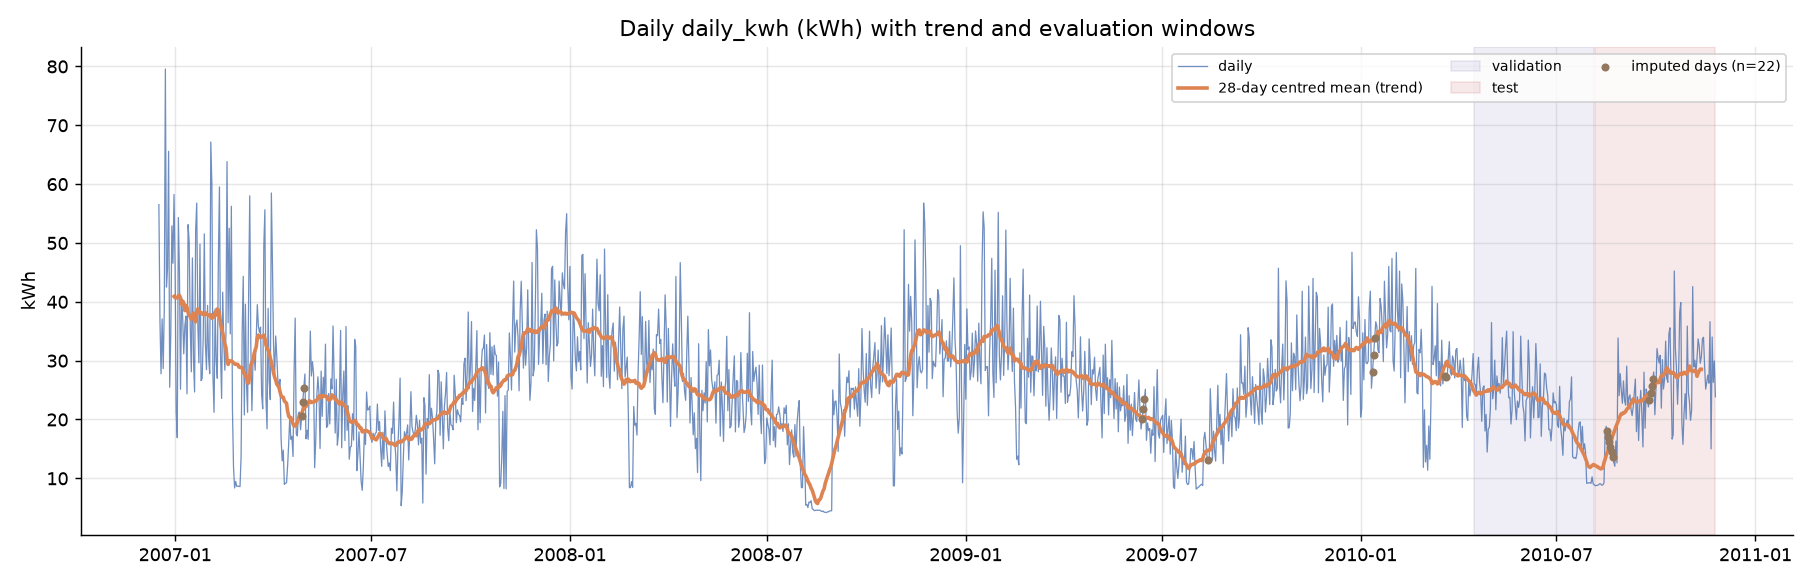

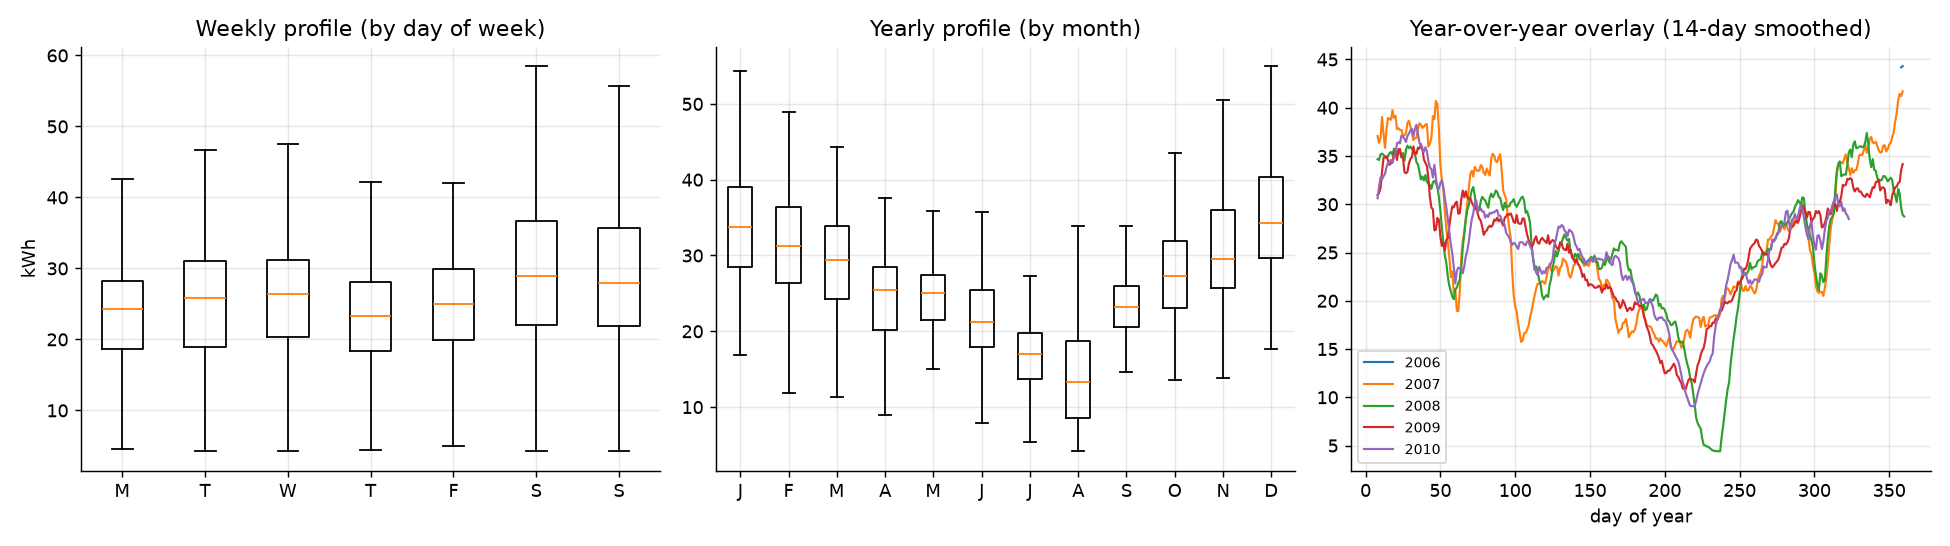

In [5]:
fig("01_series_trend.png"); fig("02_seasonality_profiles.png")

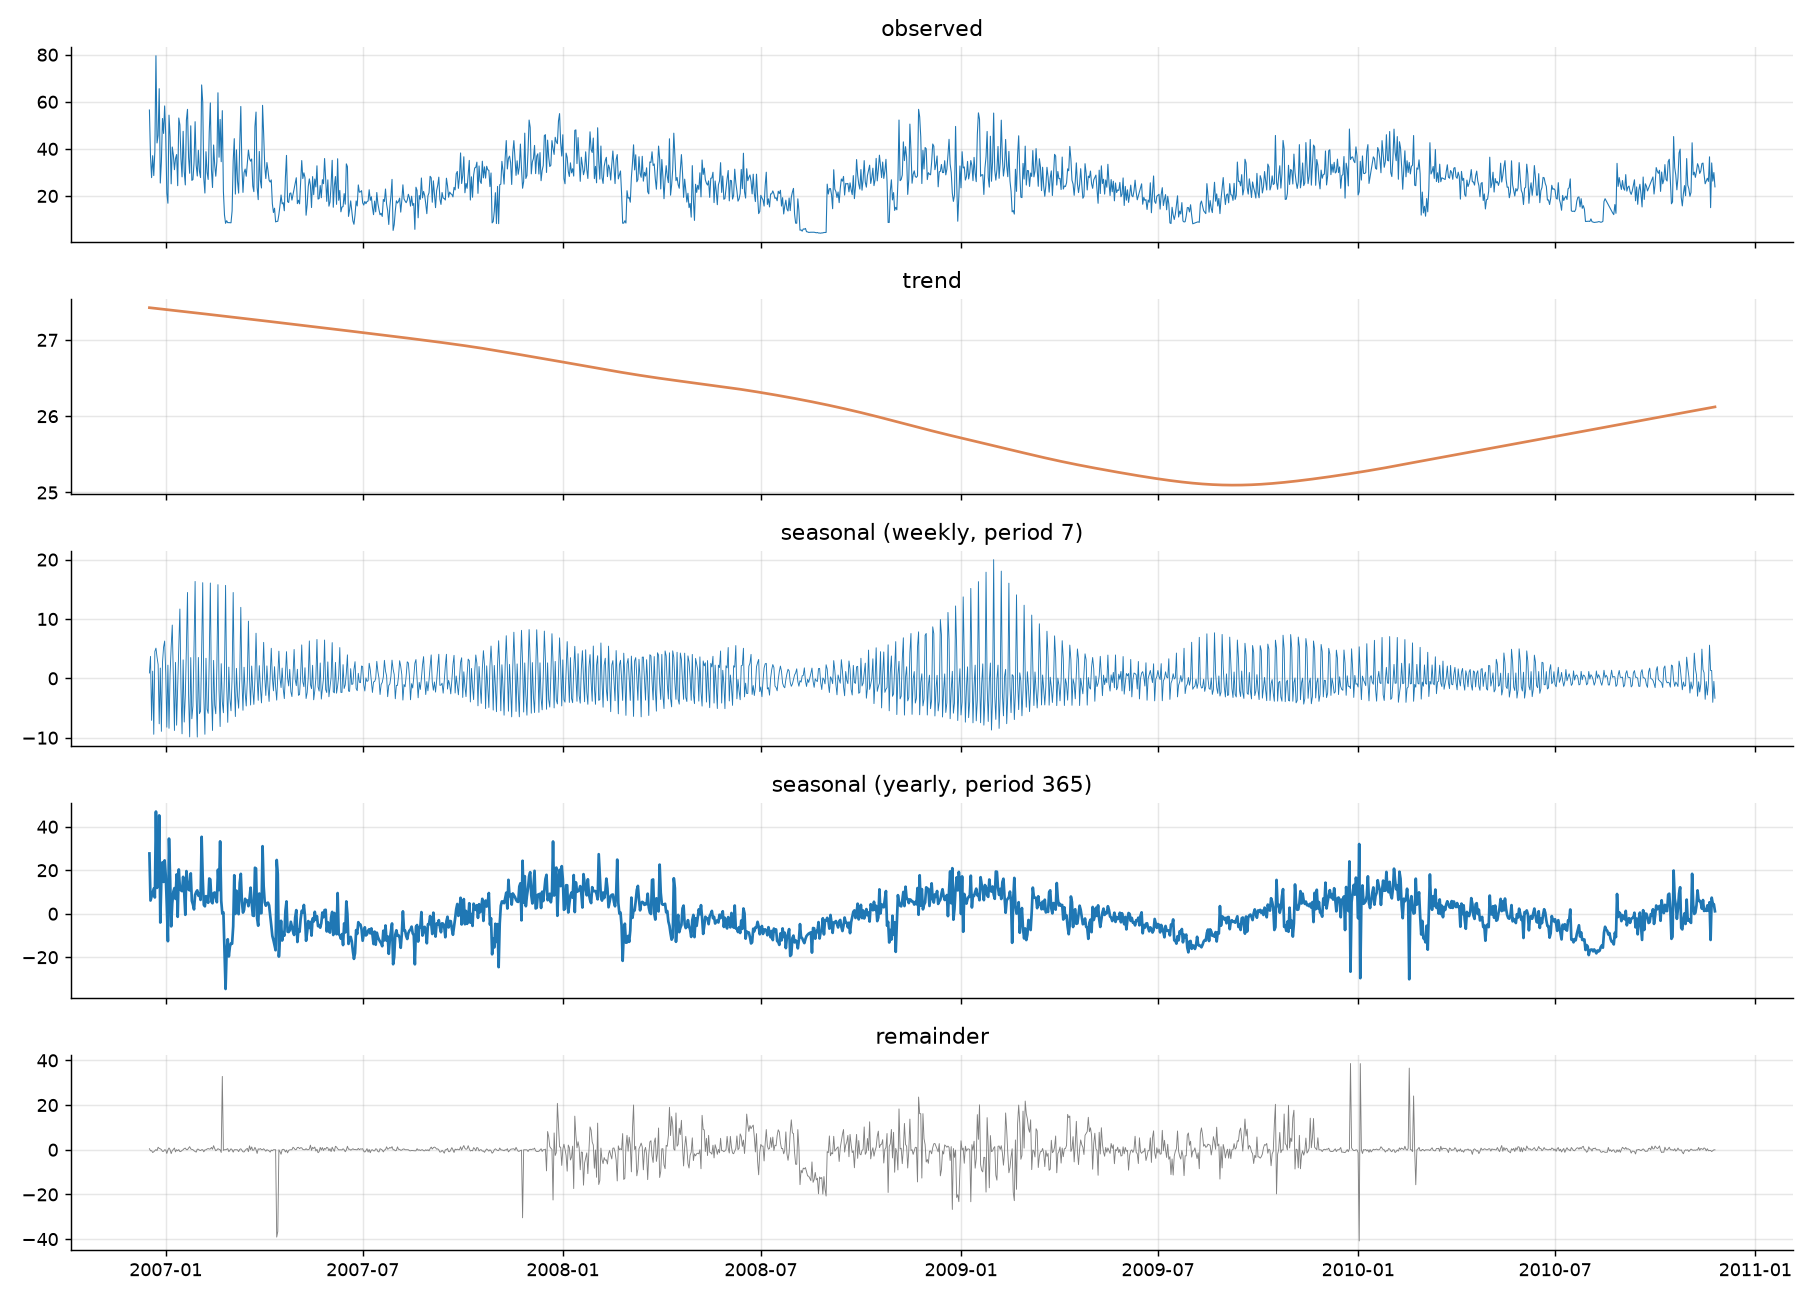

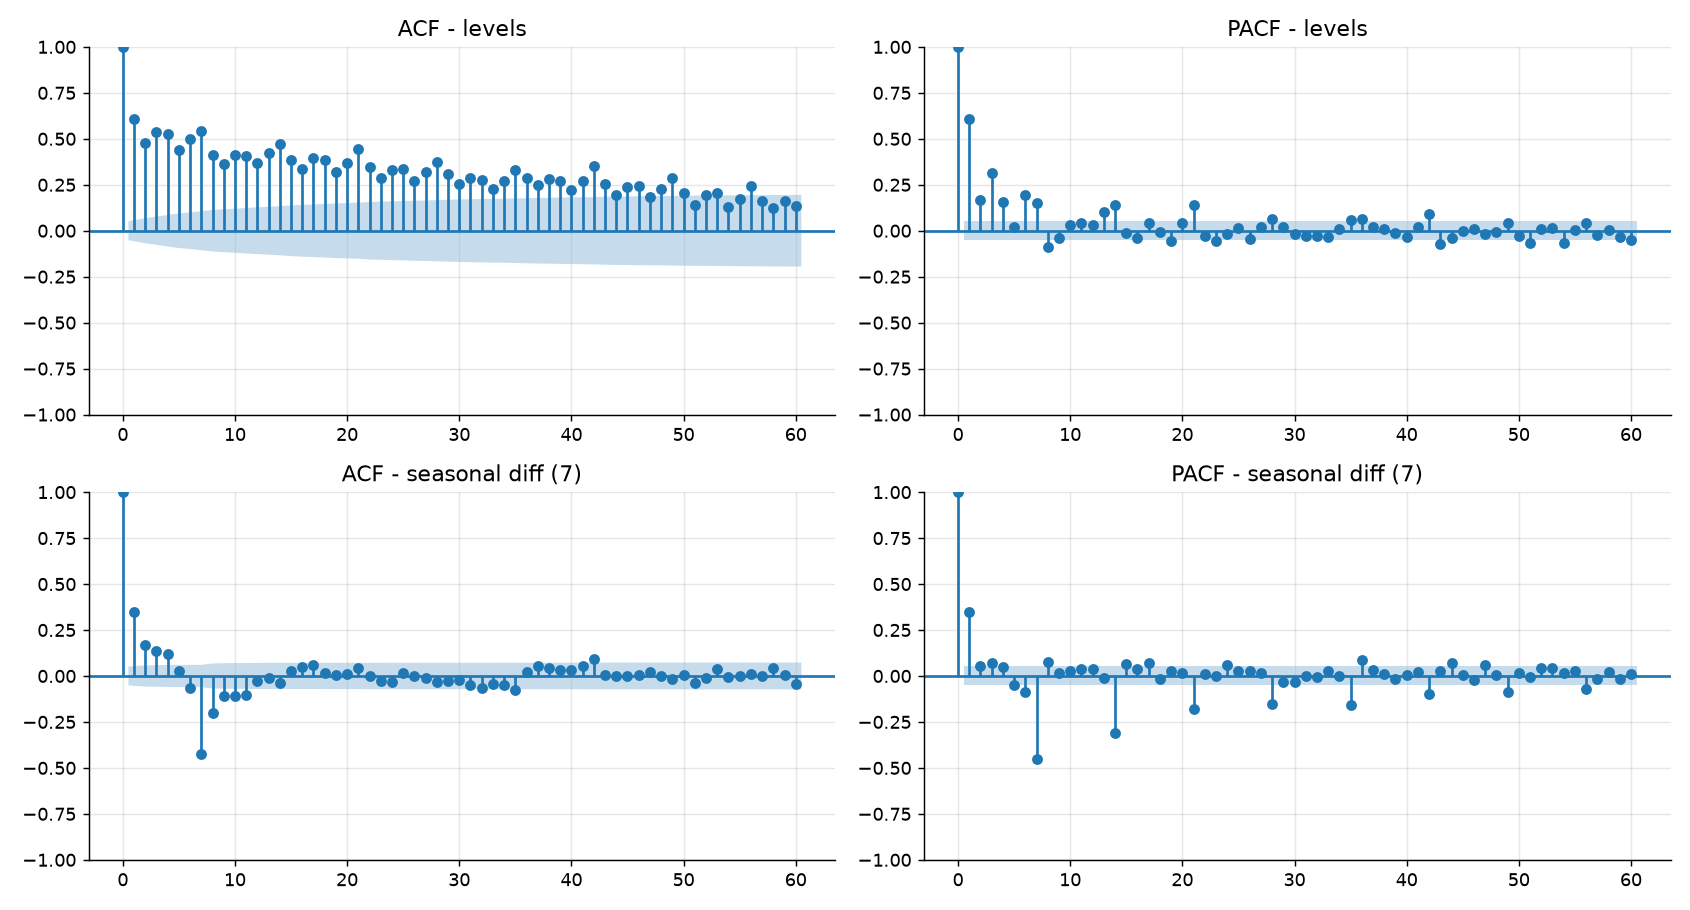

In [6]:
fig("03_mstl_decomposition.png"); fig("04_acf_pacf.png")

In [7]:
pd.DataFrame(eda["top_anomalies"])

,date,value,robust_z,type
0,2006-12-23,79.56,14.97,spike
1,2007-02-25,8.36,-12.77,dip
2,2006-12-26,65.57,11.89,spike
3,2007-02-22,56.24,11.07,spike
4,2007-02-20,52.50,10.88,spike
5,2008-11-24,53.55,10.75,spike
6,2007-03-31,58.49,10.18,spike
7,2007-01-06,25.14,-9.57,dip
8,2006-12-20,37.10,9.30,spike
9,2010-02-21,45.67,9.02,spike


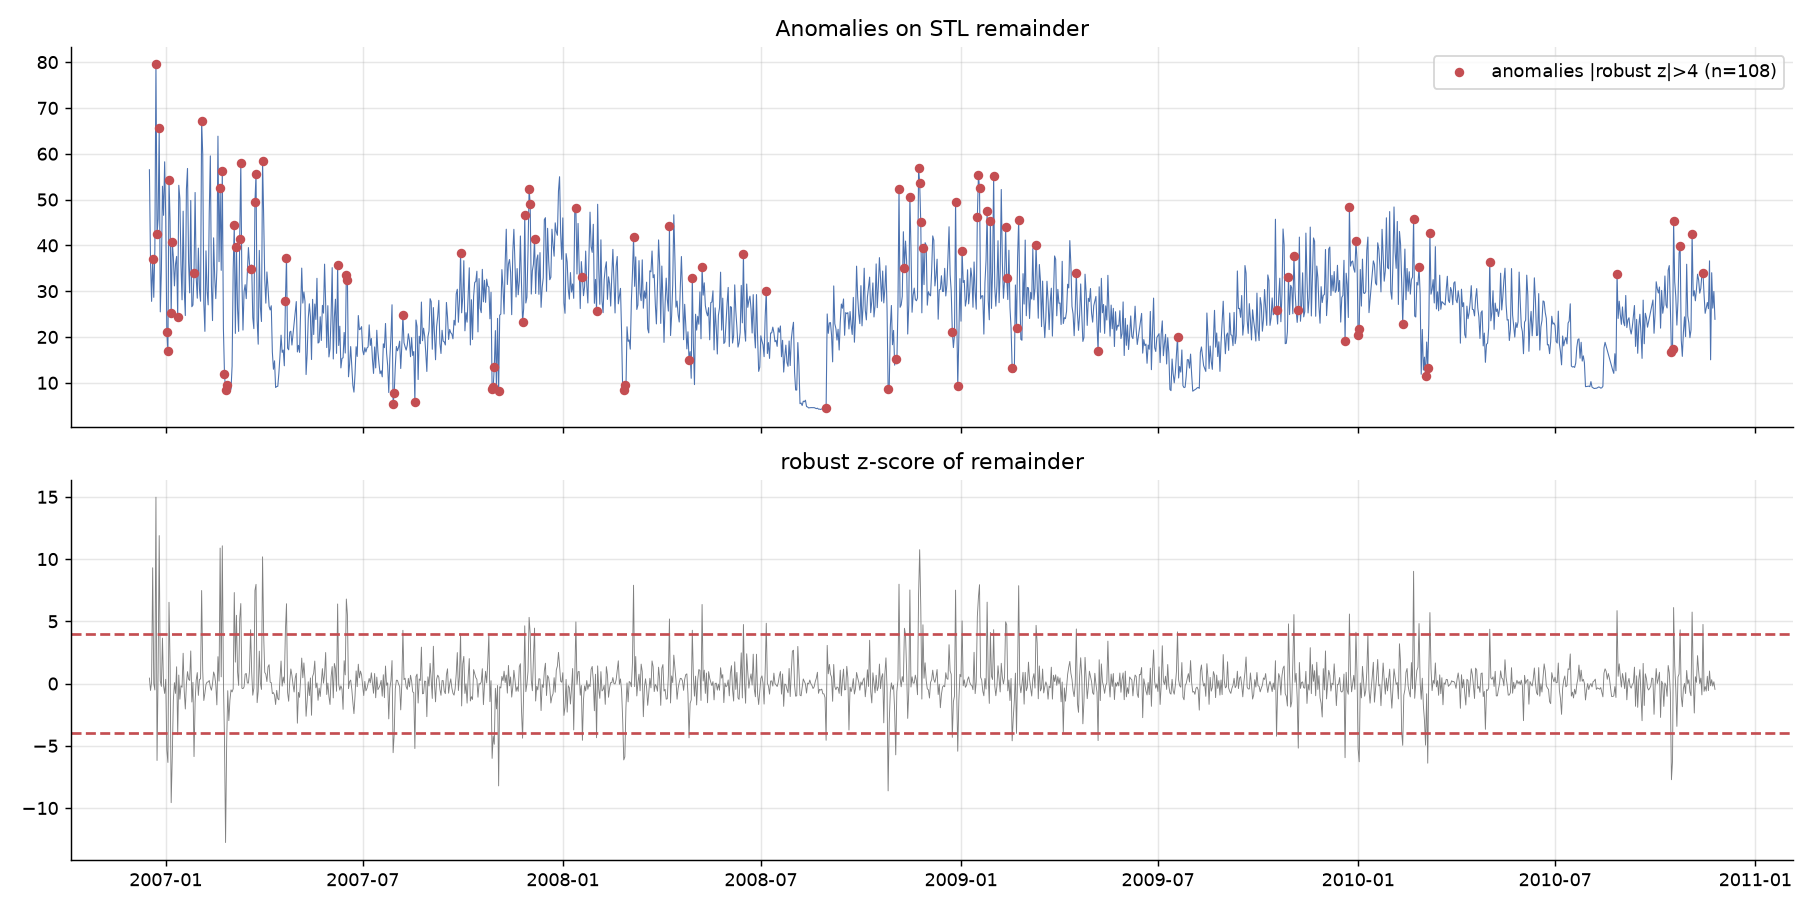

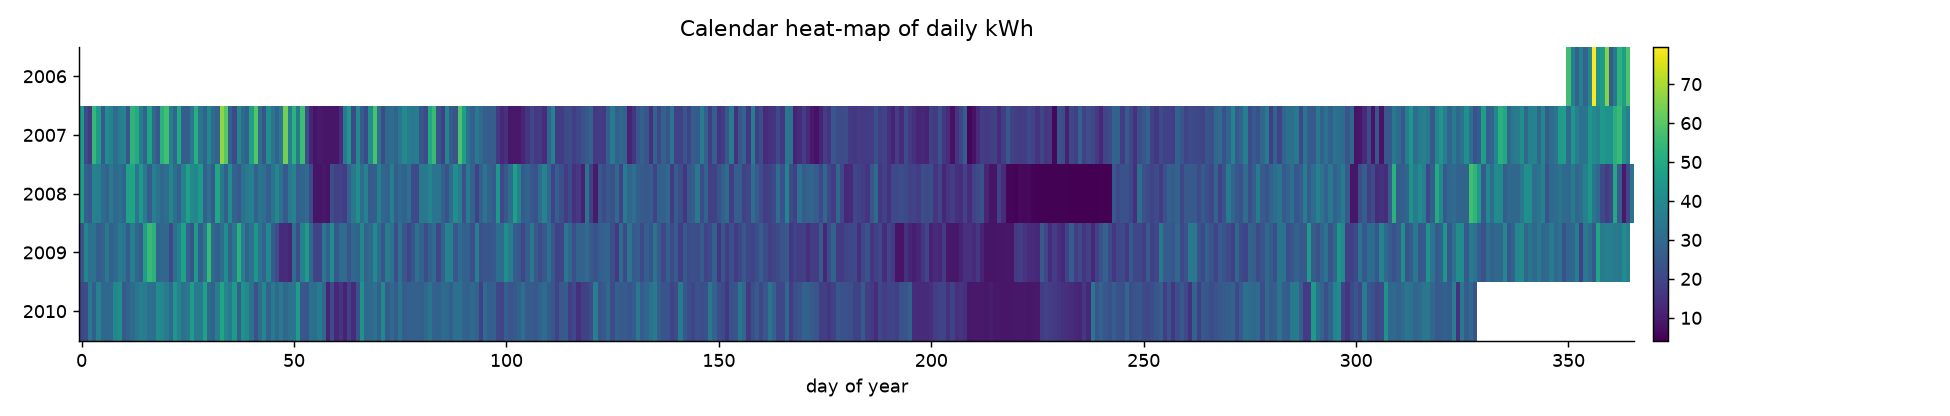

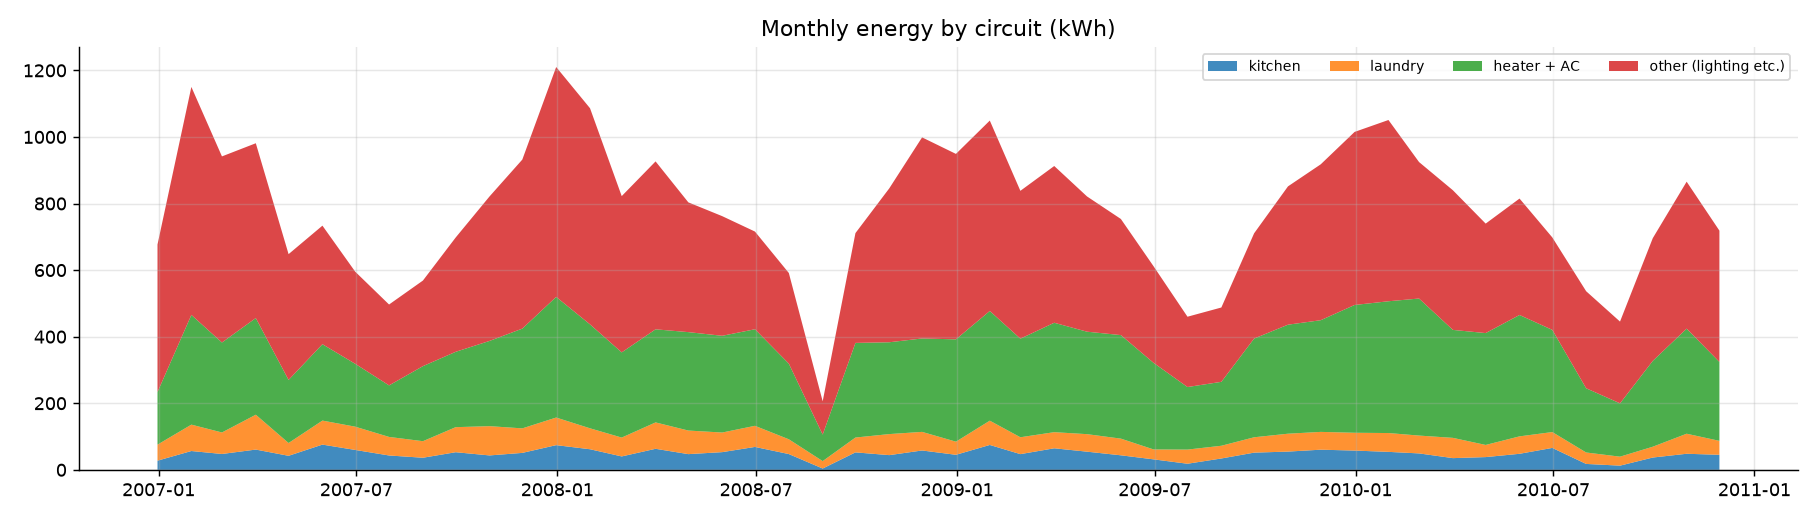

In [8]:
fig("05_anomalies.png"); fig("06_calendar_heatmap.png"); fig("07_submetering_composition.png")

## 3. Time-based features

Calendar features, cyclical encodings, holiday flags, Fourier harmonics for the yearly cycle,
and lag / rolling statistics of the target. The direct GBM uses lags shifted by the 28-day horizon.

In [9]:
from src.features import calendar_features, fourier_terms, lag_features
cal = calendar_features(y.index); four = fourier_terms(y.index, K=3); lags = lag_features(y)
display(cal.tail(3)); display(four.tail(3).round(3)); display(lags.tail(3).round(2))

,dayofweek,is_weekend,month,dayofyear,weekofyear,quarter,year,days_since_start,dow_sin,dow_cos,doy_sin,doy_cos,month_sin,month_cos,is_holiday
date,,,,,,,,,,,,,,,
2010-11-23,1,0,11,327,47,4,2010,1437,0.781831,0.623490,-0.611530,0.791221,-0.5,0.866025,0
2010-11-24,2,0,11,328,47,4,2010,1438,0.974928,-0.222521,-0.597829,0.801624,-0.5,0.866025,0
2010-11-25,3,0,11,329,47,4,2010,1439,0.433884,-0.900969,-0.583951,0.811789,-0.5,0.866025,0


,sin1_365,cos1_365,sin2_365,cos2_365,sin3_365,cos3_365
date,,,,,,
2010-11-23,-0.401,0.916,-0.735,0.678,-0.945,0.326
2010-11-24,-0.385,0.923,-0.711,0.703,-0.927,0.374
2010-11-25,-0.369,0.929,-0.687,0.727,-0.907,0.422


,lag_1,lag_2,lag_3,lag_7,lag_14,lag_21,lag_28,lag_364,roll_mean_7,roll_std_7,roll_min_7,roll_max_7,roll_mean_14,roll_std_14,roll_min_14,roll_max_14,roll_mean_28,roll_std_28,roll_min_28,roll_max_28,ewm_7,ewm_28,diff_7
date,,,,,,,,,,,,,,,,,,,,,,,
2010-11-23,34.03,15.02,36.62,25.16,33.70,19.85,15.77,35.48,27.27,6.95,15.02,36.62,29.57,5.48,15.02,36.62,27.86,6.46,15.02,42.59,28.27,28.49,4.90
2010-11-24,26.29,34.03,15.02,26.37,32.44,21.55,21.00,33.00,27.43,6.90,15.02,36.62,29.04,5.40,15.02,36.62,28.24,6.03,15.02,42.59,27.77,28.34,1.13
2010-11-25,29.94,26.29,34.03,27.54,29.56,42.59,24.39,26.66,27.94,6.94,15.02,36.62,28.87,5.32,15.02,36.62,28.56,5.86,15.02,42.59,28.31,28.45,3.57


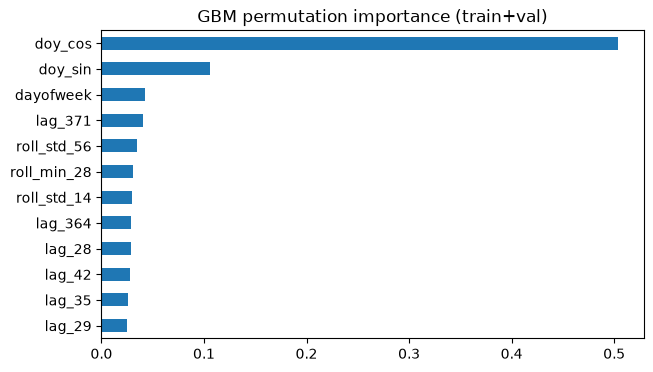

In [10]:
meta = json.load(open(M / "run_meta.json"))
imp = pd.Series(meta["gbm_importance"]).sort_values()
imp.plot.barh(figsize=(7,4), title="GBM permutation importance (train+val)"); plt.show()

## 4. Models and rolling-origin backtest

Protocol: tune on validation, refit on train+validation, then 28-day forecasts from 7 origins
spaced 14 days apart in the hold-out (196 points per model).

In [11]:
val_m = pd.read_csv(M / "validation_metrics.csv", index_col=0)
test_m = pd.read_csv(M / "test_metrics.csv", index_col=0)
display(Markdown("**Validation window**")); display(val_m.round(3))
display(Markdown("**Hold-out window**")); display(test_m.round(3))

**Validation window**

,MAE,RMSE,MAPE_%,sMAPE_%,MASE,Bias,n_points
GRU,3.422,4.291,16.861,15.911,0.485,-0.071,196.0
Ensemble(mean),3.458,4.285,16.888,16.080,0.490,-0.330,196.0
LSTM,3.487,4.349,17.357,16.225,0.494,0.013,196.0
"Prophet(cps=0.2,sps=10.0,add)",3.775,4.649,17.932,17.547,0.535,-0.931,196.0
"SARIMAX(1, 0, 2)x(1, 1, 1, 7)+F3",3.801,4.814,18.033,17.855,0.538,-1.304,196.0
"GBM(features,direct)",4.035,5.028,18.547,18.621,0.572,-1.478,196.0
SeasonalMean(4w),4.776,6.222,27.014,21.672,0.677,2.568,196.0
"SARIMA(1, 0, 2)x(1, 1, 1, 7)",4.813,6.054,27.116,21.951,0.682,2.473,196.0
LastYearScaled,4.927,6.284,22.635,23.142,0.698,-1.501,196.0
SeasonalNaive(7),5.154,6.531,26.962,23.474,0.730,1.085,196.0


**Hold-out window**

,MAE,RMSE,MAPE_%,sMAPE_%,MASE,Bias,n_points
Ensemble(mean),4.426,6.063,19.429,18.537,0.646,-0.291,196.0
GRU,4.552,6.153,20.147,19.178,0.664,-0.435,196.0
"Prophet(cps=0.2,sps=10.0,add)",4.558,6.194,20.712,19.277,0.665,0.323,196.0
LSTM,4.622,6.270,20.261,19.952,0.674,-0.762,196.0
"SARIMAX(1, 0, 2)x(1, 1, 1, 7)+F3",4.716,6.067,21.791,20.049,0.688,0.348,196.0
"SARIMA(1, 0, 2)x(1, 1, 1, 7)",5.466,6.879,22.449,23.474,0.798,-2.845,196.0
"GBM(features,direct)",6.034,7.806,26.899,29.755,0.881,-2.002,196.0
LastYearScaled,6.099,8.091,29.611,24.990,0.890,0.835,196.0
SeasonalMean(4w),6.548,7.981,27.612,30.268,0.956,-4.116,196.0
SeasonalNaive(7),6.829,8.629,28.338,30.639,0.997,-2.511,196.0


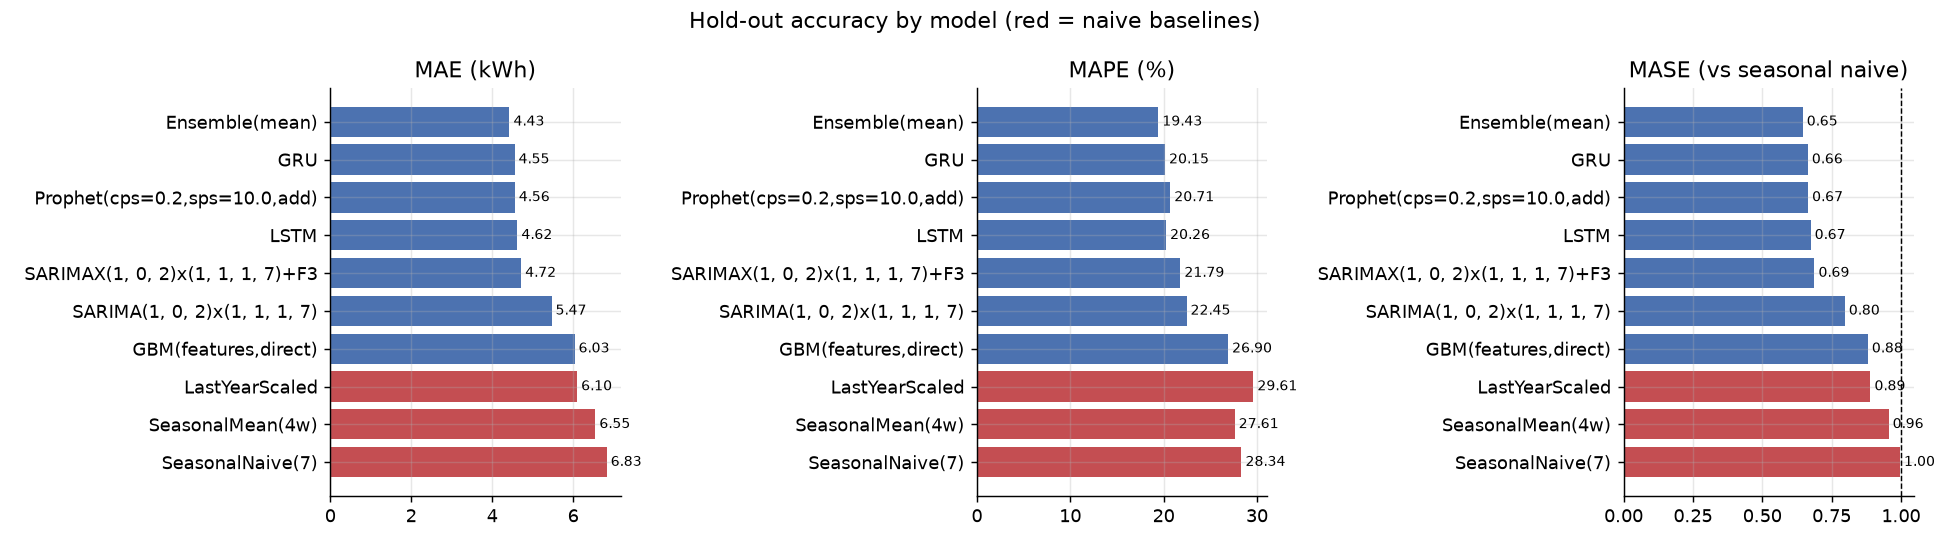

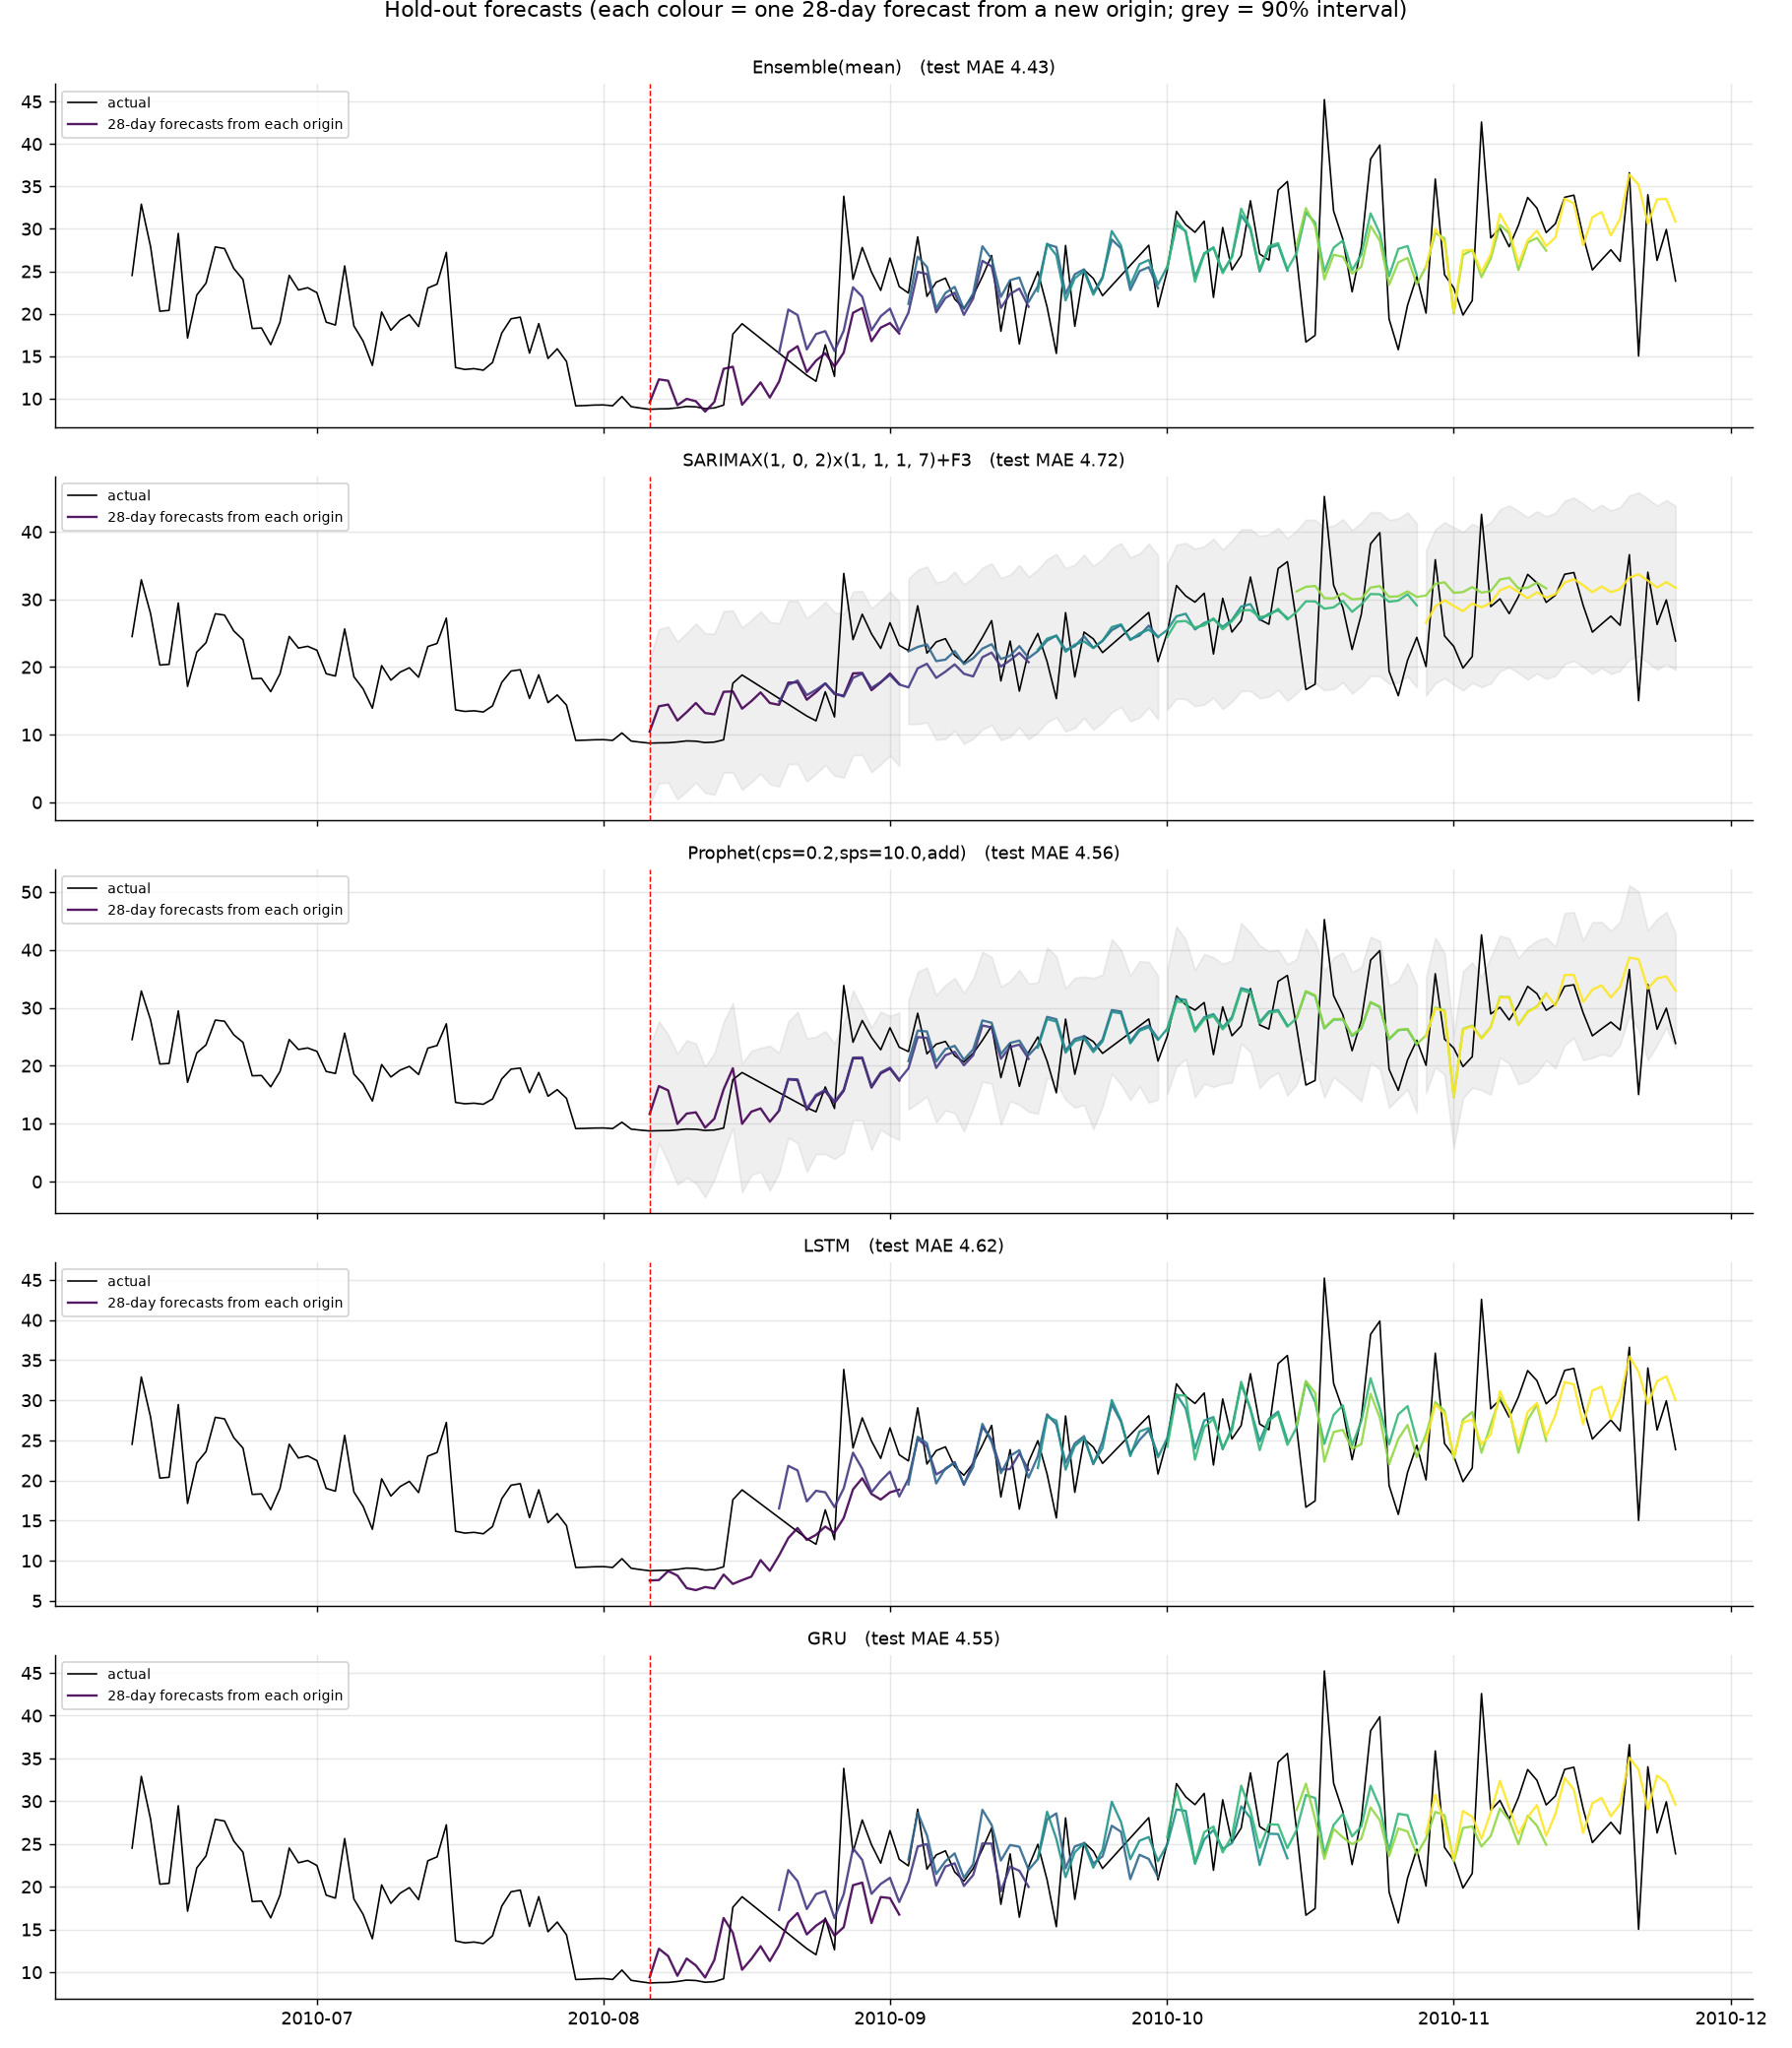

In [12]:
fig("09_test_metrics.png"); fig("11_forecasts_vs_actual.png")

### SARIMA order search and Prophet grid

In [13]:
for f in ["sarima_order_search.csv", "prophet_grid.csv", "lstm_grid.csv", "gru_grid.csv"]:
    p = M / f
    if p.exists():
        display(Markdown(f"**{f}**")); display(pd.read_csv(p).head(8))

**sarima_order_search.csv**

,order,seasonal_order,aic,bic
0,"(1, 0, 2)","(1, 1, 1, 7)",8006.733495,8067.804413
1,"(2, 0, 2)","(1, 1, 1, 7)",8009.742827,8075.902988
2,"(2, 0, 2)","(0, 1, 1, 7)",8011.875080,8072.945998
3,"(1, 0, 2)","(0, 1, 1, 7)",8012.301824,8068.283499
4,"(1, 1, 2)","(1, 1, 1, 7)",8023.191476,8084.252382
5,"(2, 1, 2)","(1, 1, 1, 7)",8023.410267,8089.559581
6,"(2, 0, 1)","(1, 1, 1, 7)",8034.437943,8095.518865
7,"(2, 0, 1)","(0, 1, 1, 7)",8036.353848,8092.344694


**prophet_grid.csv**

,cps,sps,mode,val_MAE
0,0.20,10.0,additive,3.773849
1,0.20,1.0,additive,3.782632
2,0.20,10.0,multiplicative,3.824895
3,0.20,1.0,multiplicative,3.825594
4,0.05,10.0,multiplicative,3.956636
5,0.05,1.0,multiplicative,3.960865
6,0.05,10.0,additive,3.997056
7,0.05,1.0,additive,4.009869


**lstm_grid.csv**

,hidden,layers,best_val_mse_scaled,epochs
0,32,1,0.181914,27
1,64,1,0.185680,26
2,64,2,0.181084,28


**gru_grid.csv**

,hidden,layers,best_val_mse_scaled,epochs
0,32,1,0.180559,46
1,64,1,0.178412,26
2,64,2,0.178866,32


### Live re-fit: SARIMAX with Fourier regressors on the training window

In [14]:
from src.models.arima import SarimaFourier
s = meta["sarima"]
m = SarimaFourier(order=tuple(s["order"]), seasonal_order=tuple(s["seasonal_order"]), K=s["fourier_K"], search=False).fit(train)
print(m.res_.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1_365       4.0555      0.896      4.527      0.000       2.300       5.811
cos1_365       7.7747      0.860      9.042      0.000       6.089       9.460
sin2_365      -1.7414      0.759     -2.295      0.022      -3.228      -0.254
cos2_365       1.2929      0.758      1.706      0.088      -0.193       2.779
sin3_365       1.2179      0.676      1.801      0.072      -0.107       2.543
cos3_365      -0.8267      0.691     -1.197      0.231      -2.181       0.527
ar.L1          0.8326      0.040     20.805      0.000       0.754       0.911
ma.L1         -0.4932      0.045    -10.870      0.000      -0.582      -0.404
ma.L2         -0.1092      0.032     -3.439      0.001      -0.171      -0.047
ar.S.L7        0.0141      0.002      5.908      0.000       0.009       0.019
ma.S.L7       -0.9233      0.012    -74.678      0.0

### Live re-fit: Prophet components

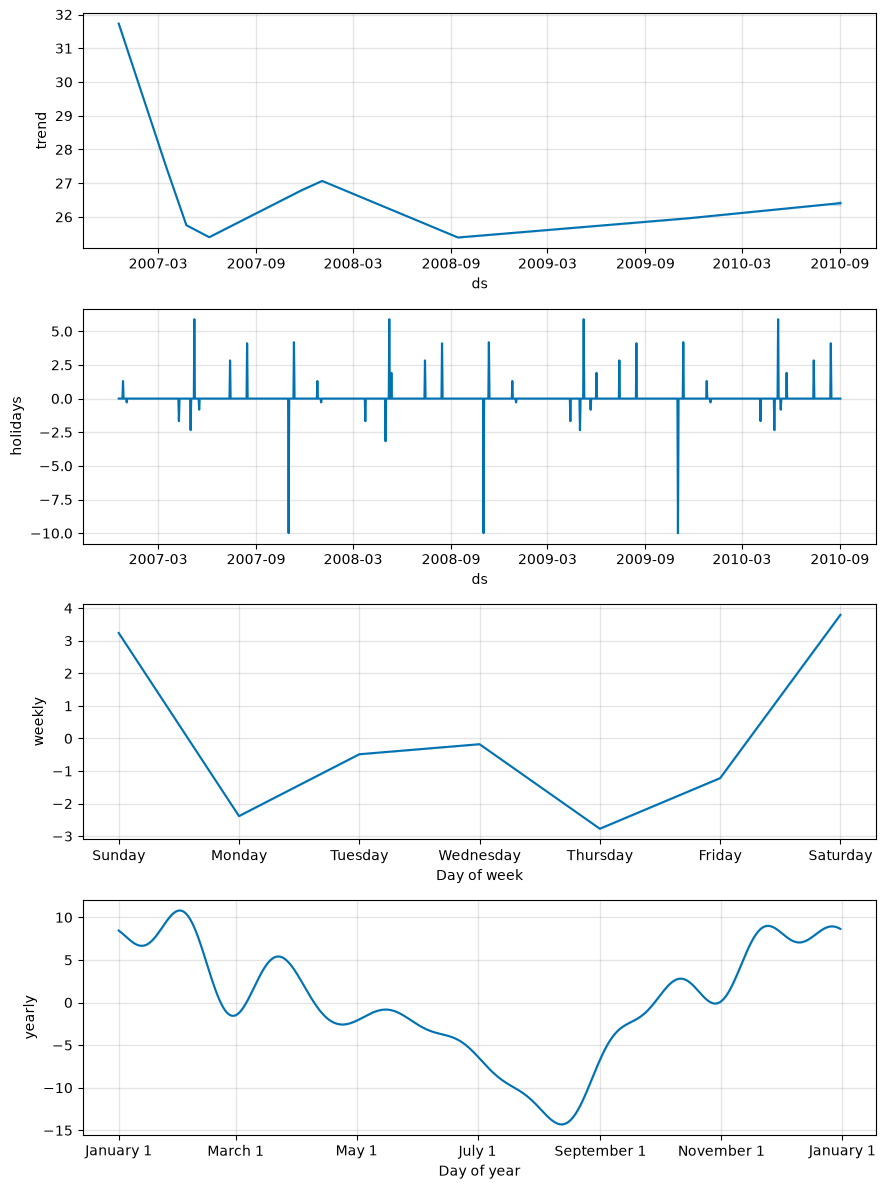

In [15]:
from src.models.prophet_model import ProphetModel
p = meta["prophet"]
pm = ProphetModel(p["cps"], p["sps"], p["mode"]).fit(pd.concat([train, val]))
future = pm.model_.make_future_dataframe(periods=28)
fcst = pm.model_.predict(future)
pm.model_.plot_components(fcst); plt.show()

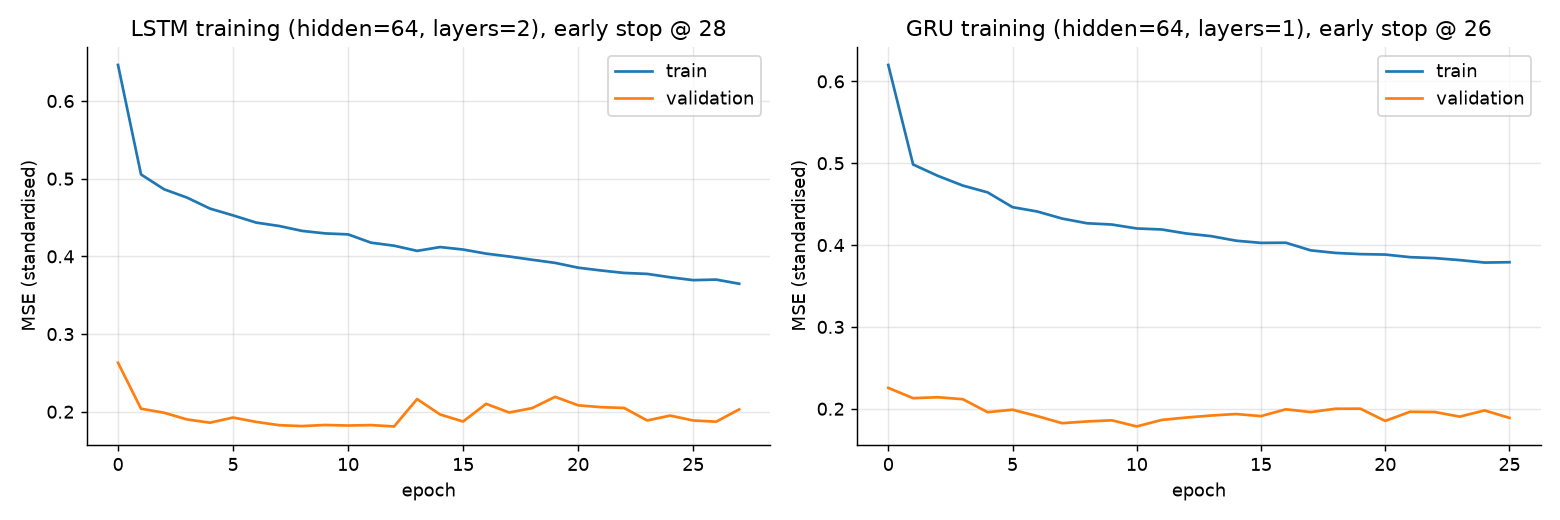

In [16]:
fig("08_rnn_training_curves.png")

## 5. Error by horizon and business impact

,Ensemble(mean),"GBM(features,direct)",GRU,LSTM,LastYearScaled,"Prophet(cps=0.2,sps=10.0,add)","SARIMA(1, 0, 2)x(1, 1, 1, 7)","SARIMAX(1, 0, 2)x(1, 1, 1, 7)+F3",SeasonalMean(4w),SeasonalNaive(7)
h,,,,,,,,,,
1,1.64,4.48,2.04,2.11,3.80,2.43,2.25,2.34,3.99,4.75
7,4.36,5.61,4.59,4.98,5.06,4.05,6.05,5.03,6.68,6.95
14,3.97,5.68,3.96,4.77,4.91,4.00,4.94,3.89,5.57,6.84
21,4.47,5.81,4.47,4.50,4.47,4.45,5.51,4.47,7.00,4.12
28,4.15,4.62,4.64,4.25,4.70,4.60,5.06,4.84,6.95,6.60


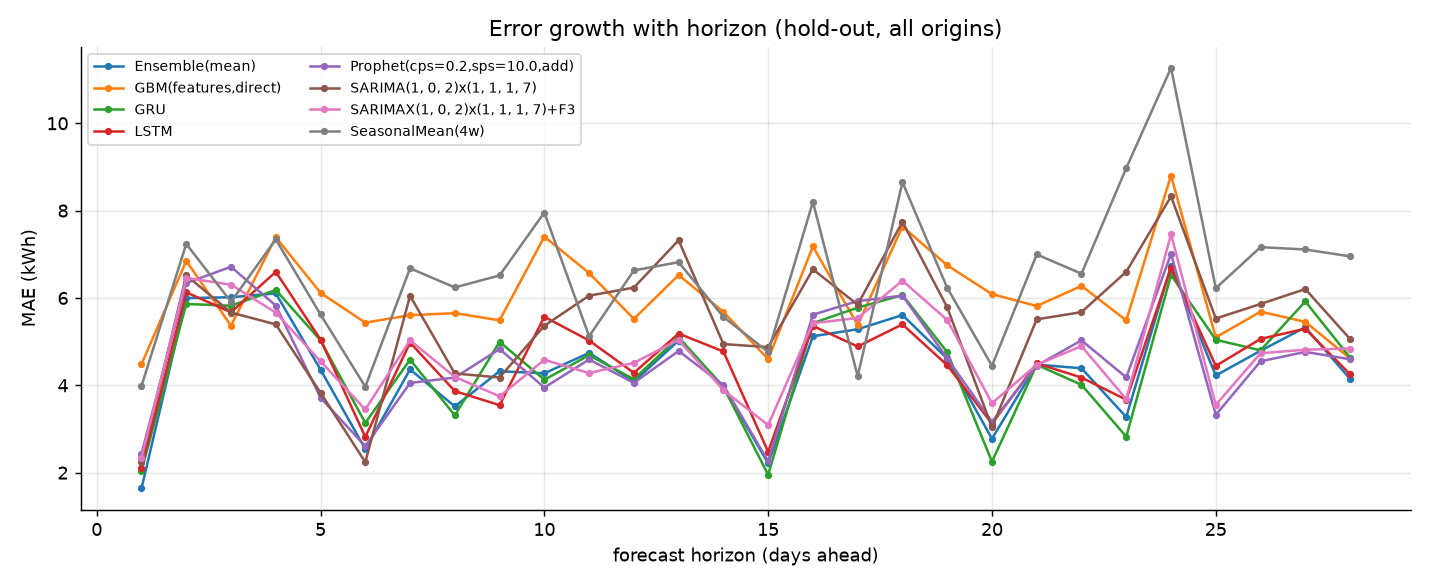

In [17]:
byh = pd.read_csv(M / "test_mae_by_horizon.csv", index_col=0)
display(byh.loc[[1,7,14,21,28]].round(2)); fig("10_mae_by_horizon.png")

,mean_abs_error,share_days_under_forecast,annual_cost_portfolio,annual_buffer_cost_portfolio
"Prophet(cps=0.2,sps=10.0,add)",4.56,0.49,12837995.65,12739566.73
"SARIMAX(1, 0, 2)x(1, 1, 1, 7)+F3",4.72,0.48,13261168.54,12546413.55
Ensemble(mean),4.43,0.53,13350296.19,14231344.65
GRU,4.55,0.53,13926956.51,13884589.89
LSTM,4.62,0.58,14608999.93,15622268.87
LastYearScaled,6.10,0.53,16588647.59,13393018.44
"SARIMA(1, 0, 2)x(1, 1, 1, 7)",5.47,0.68,20114011.82,19278271.32
"GBM(features,direct)",6.03,0.60,20542991.14,19376175.01
SeasonalNaive(7),6.83,0.61,23605568.72,23639358.83
SeasonalMean(4w),6.55,0.74,25130003.56,20915595.00


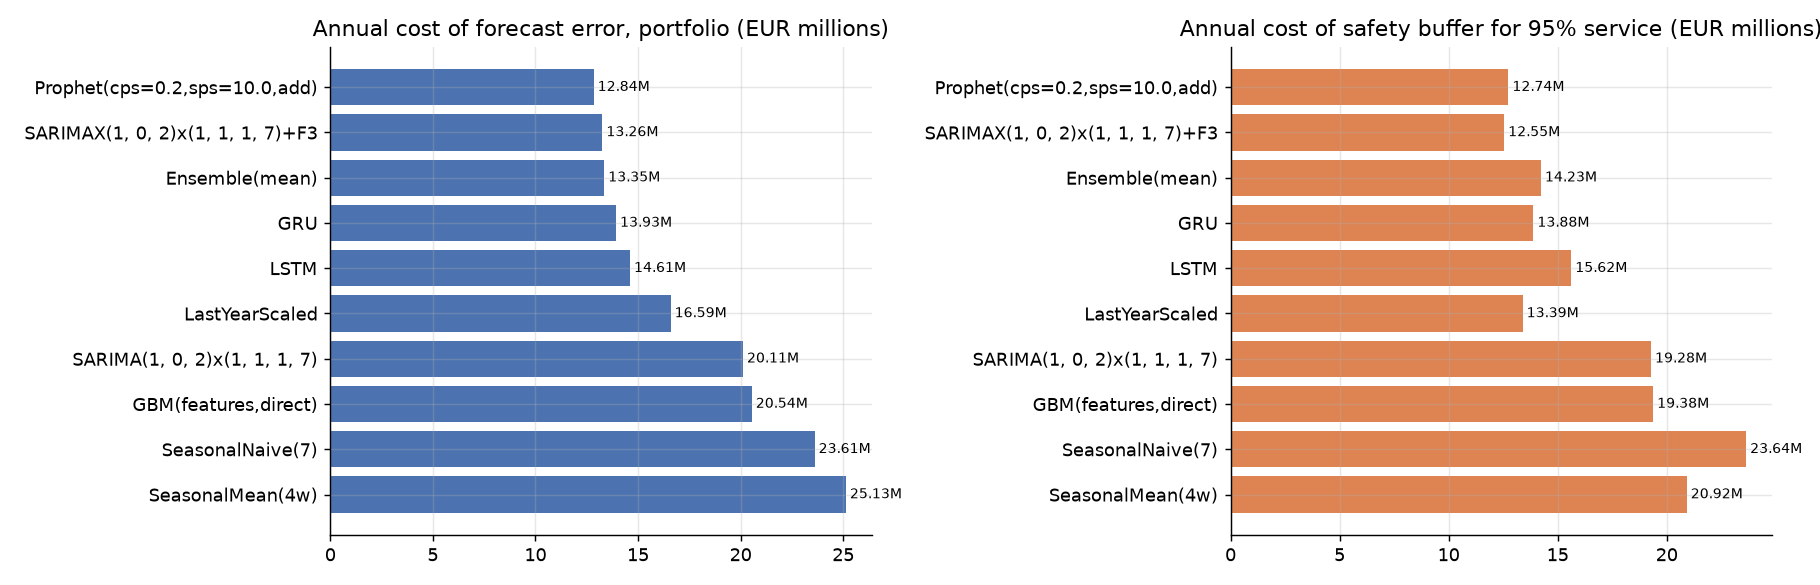

**Safety buffer calibrated on validation, service level achieved on hold-out**

,buffer_from_validation,achieved_service_level_test,buffer_share_of_mean_demand_%
model,,,
"SARIMA(1, 0, 2)x(1, 1, 1, 7)",6.745,0.745,28.201
SeasonalMean(4w),7.564,0.668,31.626
Ensemble(mean),7.573,0.929,31.665
"Prophet(cps=0.2,sps=10.0,add)",7.593,0.923,31.747
LSTM,7.902,0.929,33.039
GRU,8.202,0.929,34.295
"SARIMAX(1, 0, 2)x(1, 1, 1, 7)+F3",8.818,0.959,36.867
SeasonalNaive(7),9.142,0.811,38.224
"GBM(features,direct)",9.546,0.852,39.911


In [18]:
bt = pd.read_csv(M / "business_impact.csv", index_col=0)
cols = ["mean_abs_error","share_days_under_forecast","annual_cost_portfolio","annual_buffer_cost_portfolio"]
display(bt[cols].round(2)); fig("13_business_impact.png")
display(Markdown("**Safety buffer calibrated on validation, service level achieved on hold-out**"))
display(pd.read_csv(M / "service_level.csv", index_col=0).round(3))

## 6. Drift detection and retraining

PSI / KS on seasonally adjusted demand, Page-Hinkley and CUSUM on residuals, and a rolling-MAE
monitor, all simulated over the hold-out. The operating rules are in
`docs/retraining_and_drift_plan.md`.

,raw,seasonally_adjusted
psi,0.067,0.050
ks_stat,0.120,0.092
ks_pvalue,0.153,0.435
ref_mean,25.793,25.692
cur_mean,23.917,26.037
ref_std,8.361,NaN
cur_std,7.797,NaN


verdict: stable
Page-Hinkley alarms: [{'date': '2010-08-19', 'direction': 'down'}, {'date': '2010-08-30', 'direction': 'down'}, {'date': '2010-09-18', 'direction': 'up'}, {'date': '2010-10-14', 'direction': 'down'}, {'date': '2010-10-17', 'direction': 'up'}, {'date': '2010-10-19', 'direction': 'down'}, {'date': '2010-10-25', 'direction': 'up'}]
CUSUM alarms: []


,value
test_mae_live,4.354
test_bias_live,-0.412
days_in_alarm,25.000
share_days_in_alarm,0.255
max_rolling_mae,6.558


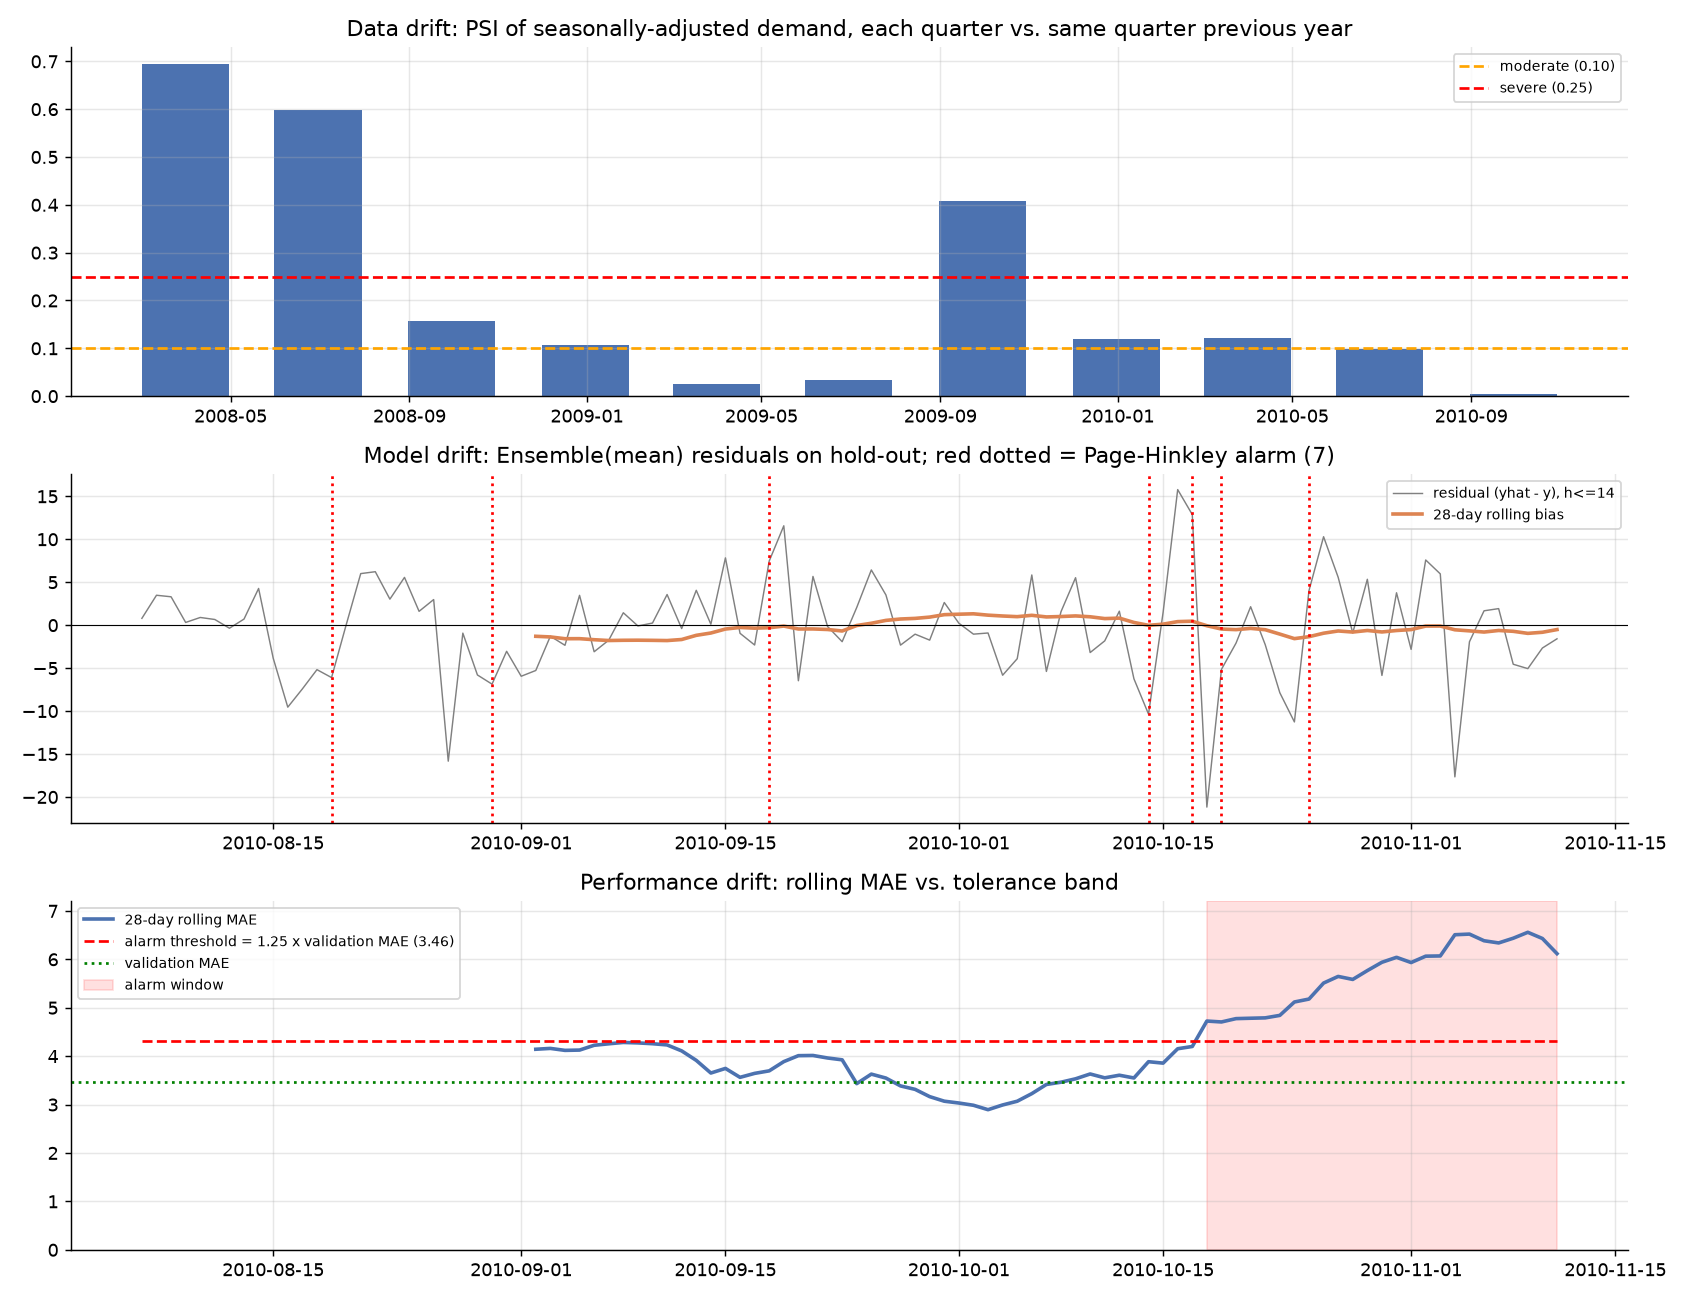

In [19]:
drift = json.load(open(M / "drift_report.json"))
dd = drift["distribution_drift_train_vs_test"]
display(pd.DataFrame({"raw": dd["raw"], "seasonally_adjusted": dd["seasonally_adjusted"]}).round(3))
print("verdict:", dd["verdict"]); print("Page-Hinkley alarms:", drift["page_hinkley_alarms"])
print("CUSUM alarms:", drift["cusum_alarms"]); display(pd.Series(drift["performance"]).round(3).to_frame("value"))
fig("12_drift_monitoring.png")

In [20]:
# live: PSI of the latest 90 days vs the same window a year earlier, seasonally adjusted
from src.drift import psi, seasonal_adjust
adj = seasonal_adjust(y)
cur = adj.iloc[-90:]; prev = adj.loc[cur.index - pd.Timedelta(days=365)]
print(f"PSI last 90 days vs previous year: {psi(prev.values, cur.values):.3f}")

PSI last 90 days vs previous year: 0.111


### Retraining plan in one table

| cadence | action |
|---|---|
| daily | ingest + data checks, Prophet refit, SARIMAX filter update, residual monitors |
| weekly | SARIMAX + GBM refit, PSI/KS drift check, interval coverage |
| monthly | LSTM/GRU retrain, ensemble re-weighting, champion/challenger |
| quarterly | SARIMA order and GBM hyper-parameter re-selection, cost assumptions review |
| on alarm | triggered retrain with backtest gate and rollback |